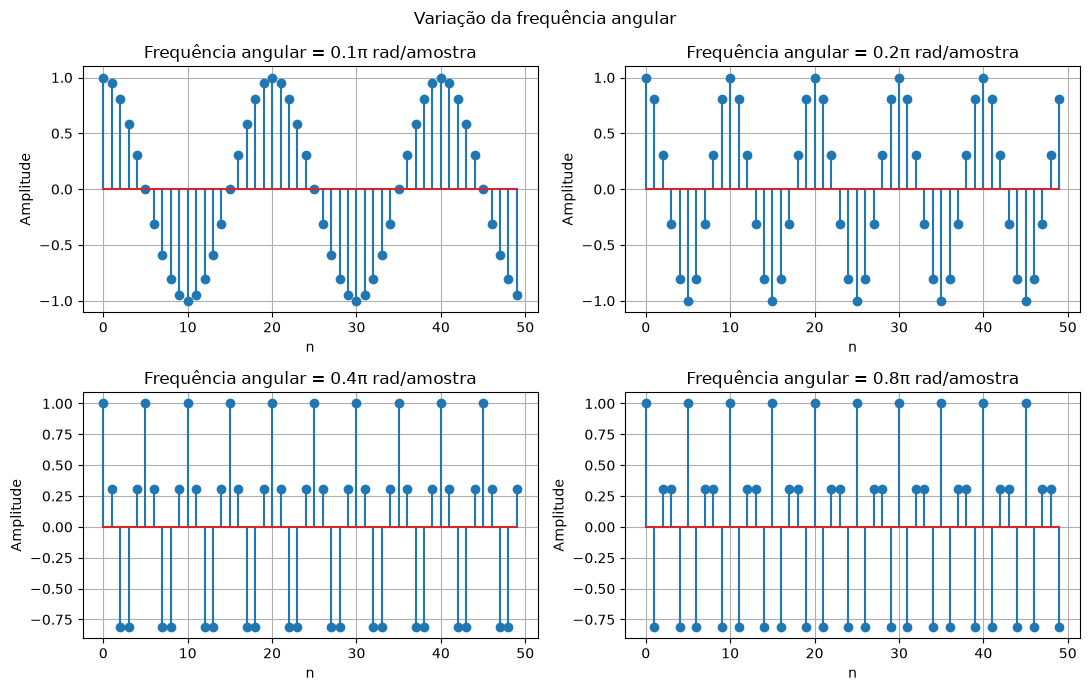

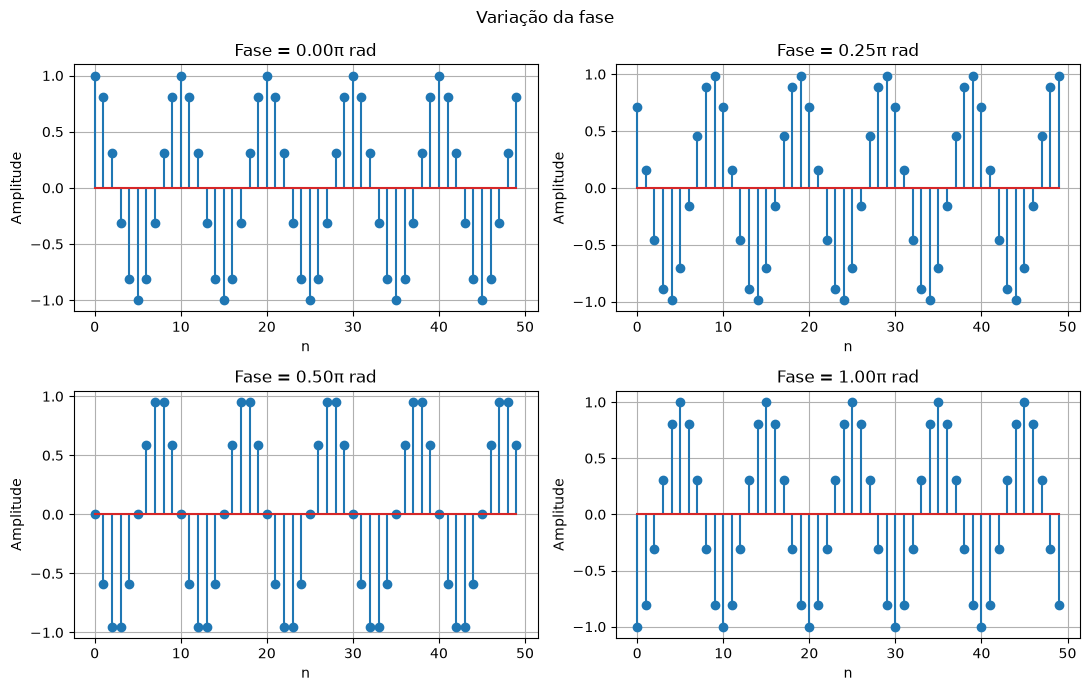

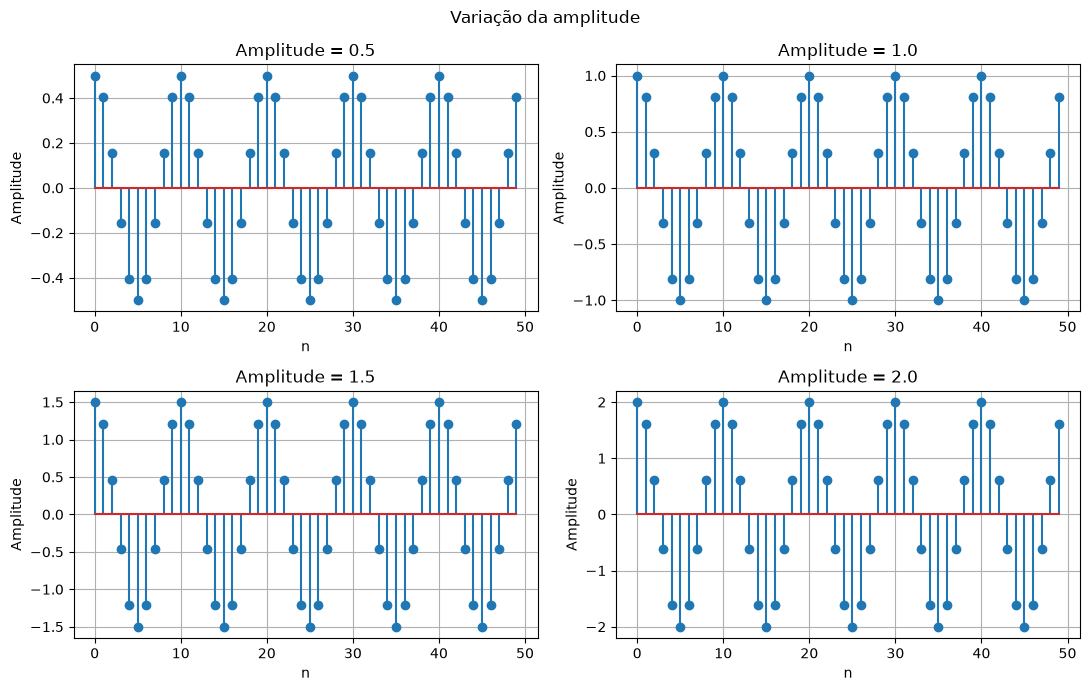

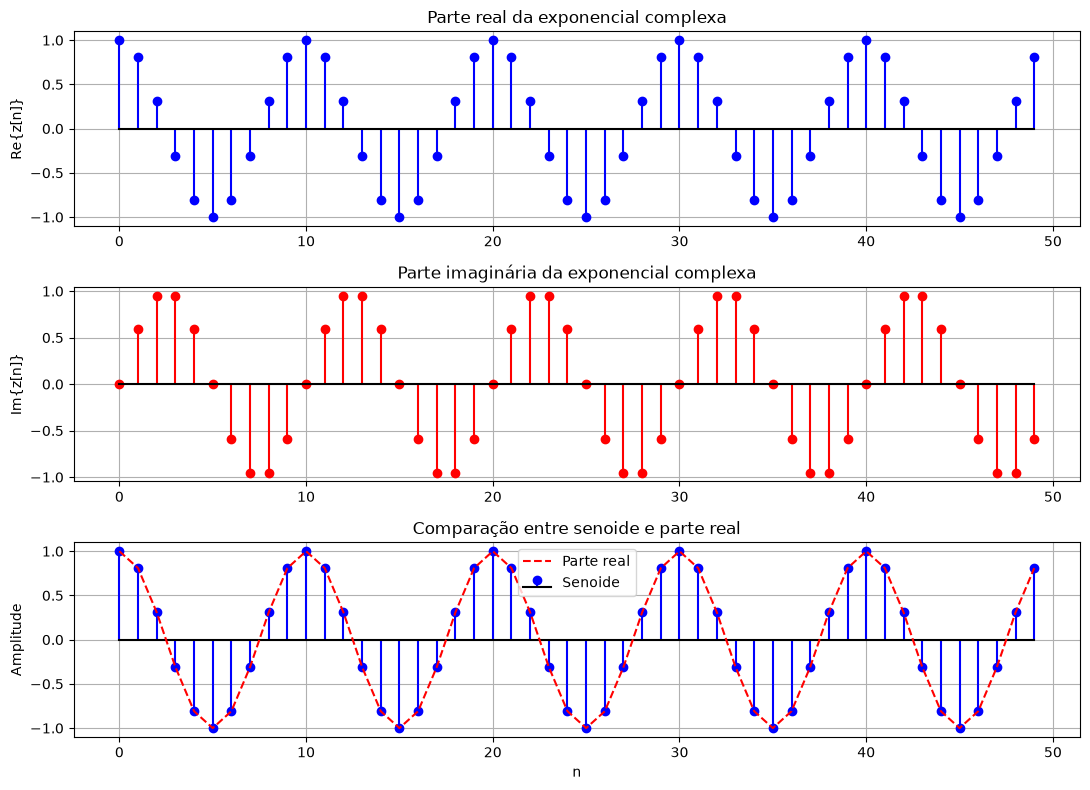

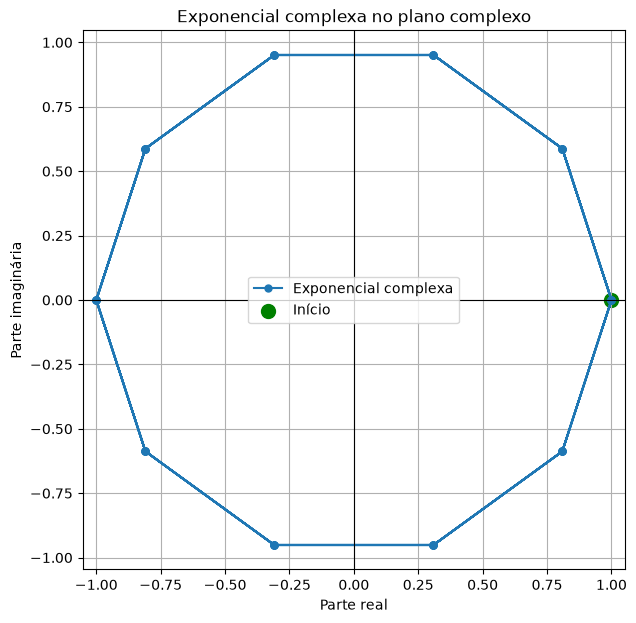

Verificação da relação de Euler
--------------------------------
Erro máximo na identidade do cosseno: 0.0
Erro máximo na identidade do seno: 0.0

Simulações concluídas!


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURAÇÕES GERAIS
# ============================================================

n = np.arange(0, 50)  # Índices de tempo discreto

# Parâmetros da senoide de referência
A = 1.0
w0 = 0.2 * np.pi       # Frequência angular (rad/amostra)
phi = 0.0              # Fase (rad)


# ============================================================
# FUNÇÕES DE GERAÇÃO DOS SINAIS
# ============================================================

def senoide(A, w0, phi, n):
    """Gera uma senoide discreta."""
    return A * np.cos(w0 * n + phi)


def exponencial_complexa(A, w0, phi, n):
    """Gera uma exponencial complexa discreta."""
    return A * np.exp(1j * (w0 * n + phi))


# ============================================================
# 1. VARIAÇÃO DA FREQUÊNCIA
# ============================================================

frequencias = [
    0.1 * np.pi,
    0.2 * np.pi,
    0.4 * np.pi,
    0.8 * np.pi
]

plt.figure(figsize=(11, 7))

for i, w in enumerate(frequencias):
    x = senoide(A, w, phi, n)

    plt.subplot(2, 2, i + 1)
    plt.stem(n, x)
    plt.title(f"Frequência angular = {w/np.pi:.1f}π rad/amostra")
    plt.xlabel("n")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.suptitle("Variação da frequência angular")
plt.tight_layout()
plt.show()


# ============================================================
# 2. VARIAÇÃO DA FASE
# ============================================================

fases = [
    0,
    np.pi / 4,
    np.pi / 2,
    np.pi
]

plt.figure(figsize=(11, 7))

for i, fase in enumerate(fases):
    x = senoide(A, w0, fase, n)

    plt.subplot(2, 2, i + 1)
    plt.stem(n, x)
    plt.title(f"Fase = {fase/np.pi:.2f}π rad")
    plt.xlabel("n")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.suptitle("Variação da fase")
plt.tight_layout()
plt.show()


# ============================================================
# 3. VARIAÇÃO DA AMPLITUDE
# ============================================================

amplitudes = [0.5, 1.0, 1.5, 2.0]

plt.figure(figsize=(11, 7))

for i, amp in enumerate(amplitudes):
    x = senoide(amp, w0, phi, n)

    plt.subplot(2, 2, i + 1)
    plt.stem(n, x)
    plt.title(f"Amplitude = {amp}")
    plt.xlabel("n")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.suptitle("Variação da amplitude")
plt.tight_layout()
plt.show()


# ============================================================
# 4. SENOIDE E EXPONENCIAL COMPLEXA
# ============================================================

z = exponencial_complexa(A, w0, phi, n)

parte_real = np.real(z)
parte_imaginaria = np.imag(z)

# Senoide original
x = senoide(A, w0, phi, n)

plt.figure(figsize=(11, 8))

# Parte real
plt.subplot(3, 1, 1)
plt.stem(n, parte_real, linefmt='b-', markerfmt='bo',
         basefmt='k-')
plt.title("Parte real da exponencial complexa")
plt.ylabel("Re{z[n]}")
plt.grid(True)

# Parte imaginária
plt.subplot(3, 1, 2)
plt.stem(n, parte_imaginaria, linefmt='r-', markerfmt='ro',
         basefmt='k-')
plt.title("Parte imaginária da exponencial complexa")
plt.ylabel("Im{z[n]}")
plt.grid(True)

# Comparação entre a senoide e a parte real
plt.subplot(3, 1, 3)
plt.stem(n, x, linefmt='b-', markerfmt='bo',
         basefmt='k-', label='Senoide')
plt.plot(n, parte_real, 'r--', label='Parte real')
plt.title("Comparação entre senoide e parte real")
plt.xlabel("n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 5. REPRESENTAÇÃO NO PLANO COMPLEXO
# ============================================================

plt.figure(figsize=(7, 7))

plt.plot(parte_real, parte_imaginaria, 'o-',
         markersize=5, label='Exponencial complexa')

plt.scatter(parte_real[0], parte_imaginaria[0],
            color='green', s=100, label='Início')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)

plt.title("Exponencial complexa no plano complexo")
plt.xlabel("Parte real")
plt.ylabel("Parte imaginária")
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# 6. VERIFICAÇÃO DA RELAÇÃO DE EULER
# ============================================================

# Identidade:
# cos(theta) = (exp(j*theta) + exp(-j*theta))/2

theta = w0 * n

cos_original = np.cos(theta)

cos_euler = (
    np.exp(1j * theta) + np.exp(-1j * theta)
) / 2

# Identidade:
# sin(theta) = (exp(j*theta) - exp(-j*theta))/(2j)

sin_original = np.sin(theta)

sin_euler = (
    np.exp(1j * theta) - np.exp(-1j * theta)
) / (2j)

print("Verificação da relação de Euler")
print("--------------------------------")
print("Erro máximo na identidade do cosseno:",
      np.max(np.abs(cos_original - cos_euler)))

print("Erro máximo na identidade do seno:",
      np.max(np.abs(sin_original - sin_euler)))

print("\nSimulações concluídas!")
